# 1. Portada e introducción

**Micro proyecto 1 — Generación de bocetos (Sketch-RNN)**
Curso: Modelos Avanzados de Procesamiento de Lenguaje Natural — MAIA

- **Estudiante:** Maria Fernanda Hurtado, Johana Nataly Tinoco, Ivan Eduardo Rincon, Zenon Jorge Alano, Luisa Aristizabal.
- **Categoría seleccionada:** `apple` (manzana)

## Resumen del proyecto

Se entrena desde cero, en PyTorch, un modelo recurrente capaz de **generar bocetos nuevos de manzanas**
a partir de los dibujos de la categoría `apple` del dataset *Quick, Draw!* (versión sketch-rnn).
Cada boceto es una secuencia de movimientos del lápiz; el modelo recibe los puntos anteriores y predice el
siguiente punto, compuesto por dos salidas numéricas (Δx, Δy) y una salida categórica (`pen_state`, 3 clases).

Se respetan los límites obligatorios: **16.000 / 2.000 / 2.000** bocetos (train / validación / prueba, tomados de
los conjuntos del `.npz`) y **máximo 200 puntos por boceto**. El relleno (*padding*) se enmascara tanto en la
pérdida como en las métricas. Sobre el conjunto de prueba se reportan el **MSE** de Δx y Δy, el **F1 macro** de
`pen_state` y el valor de la **función de pérdida**, y se generan bocetos completos guardados como PNG.

## Diagrama de la arquitectura

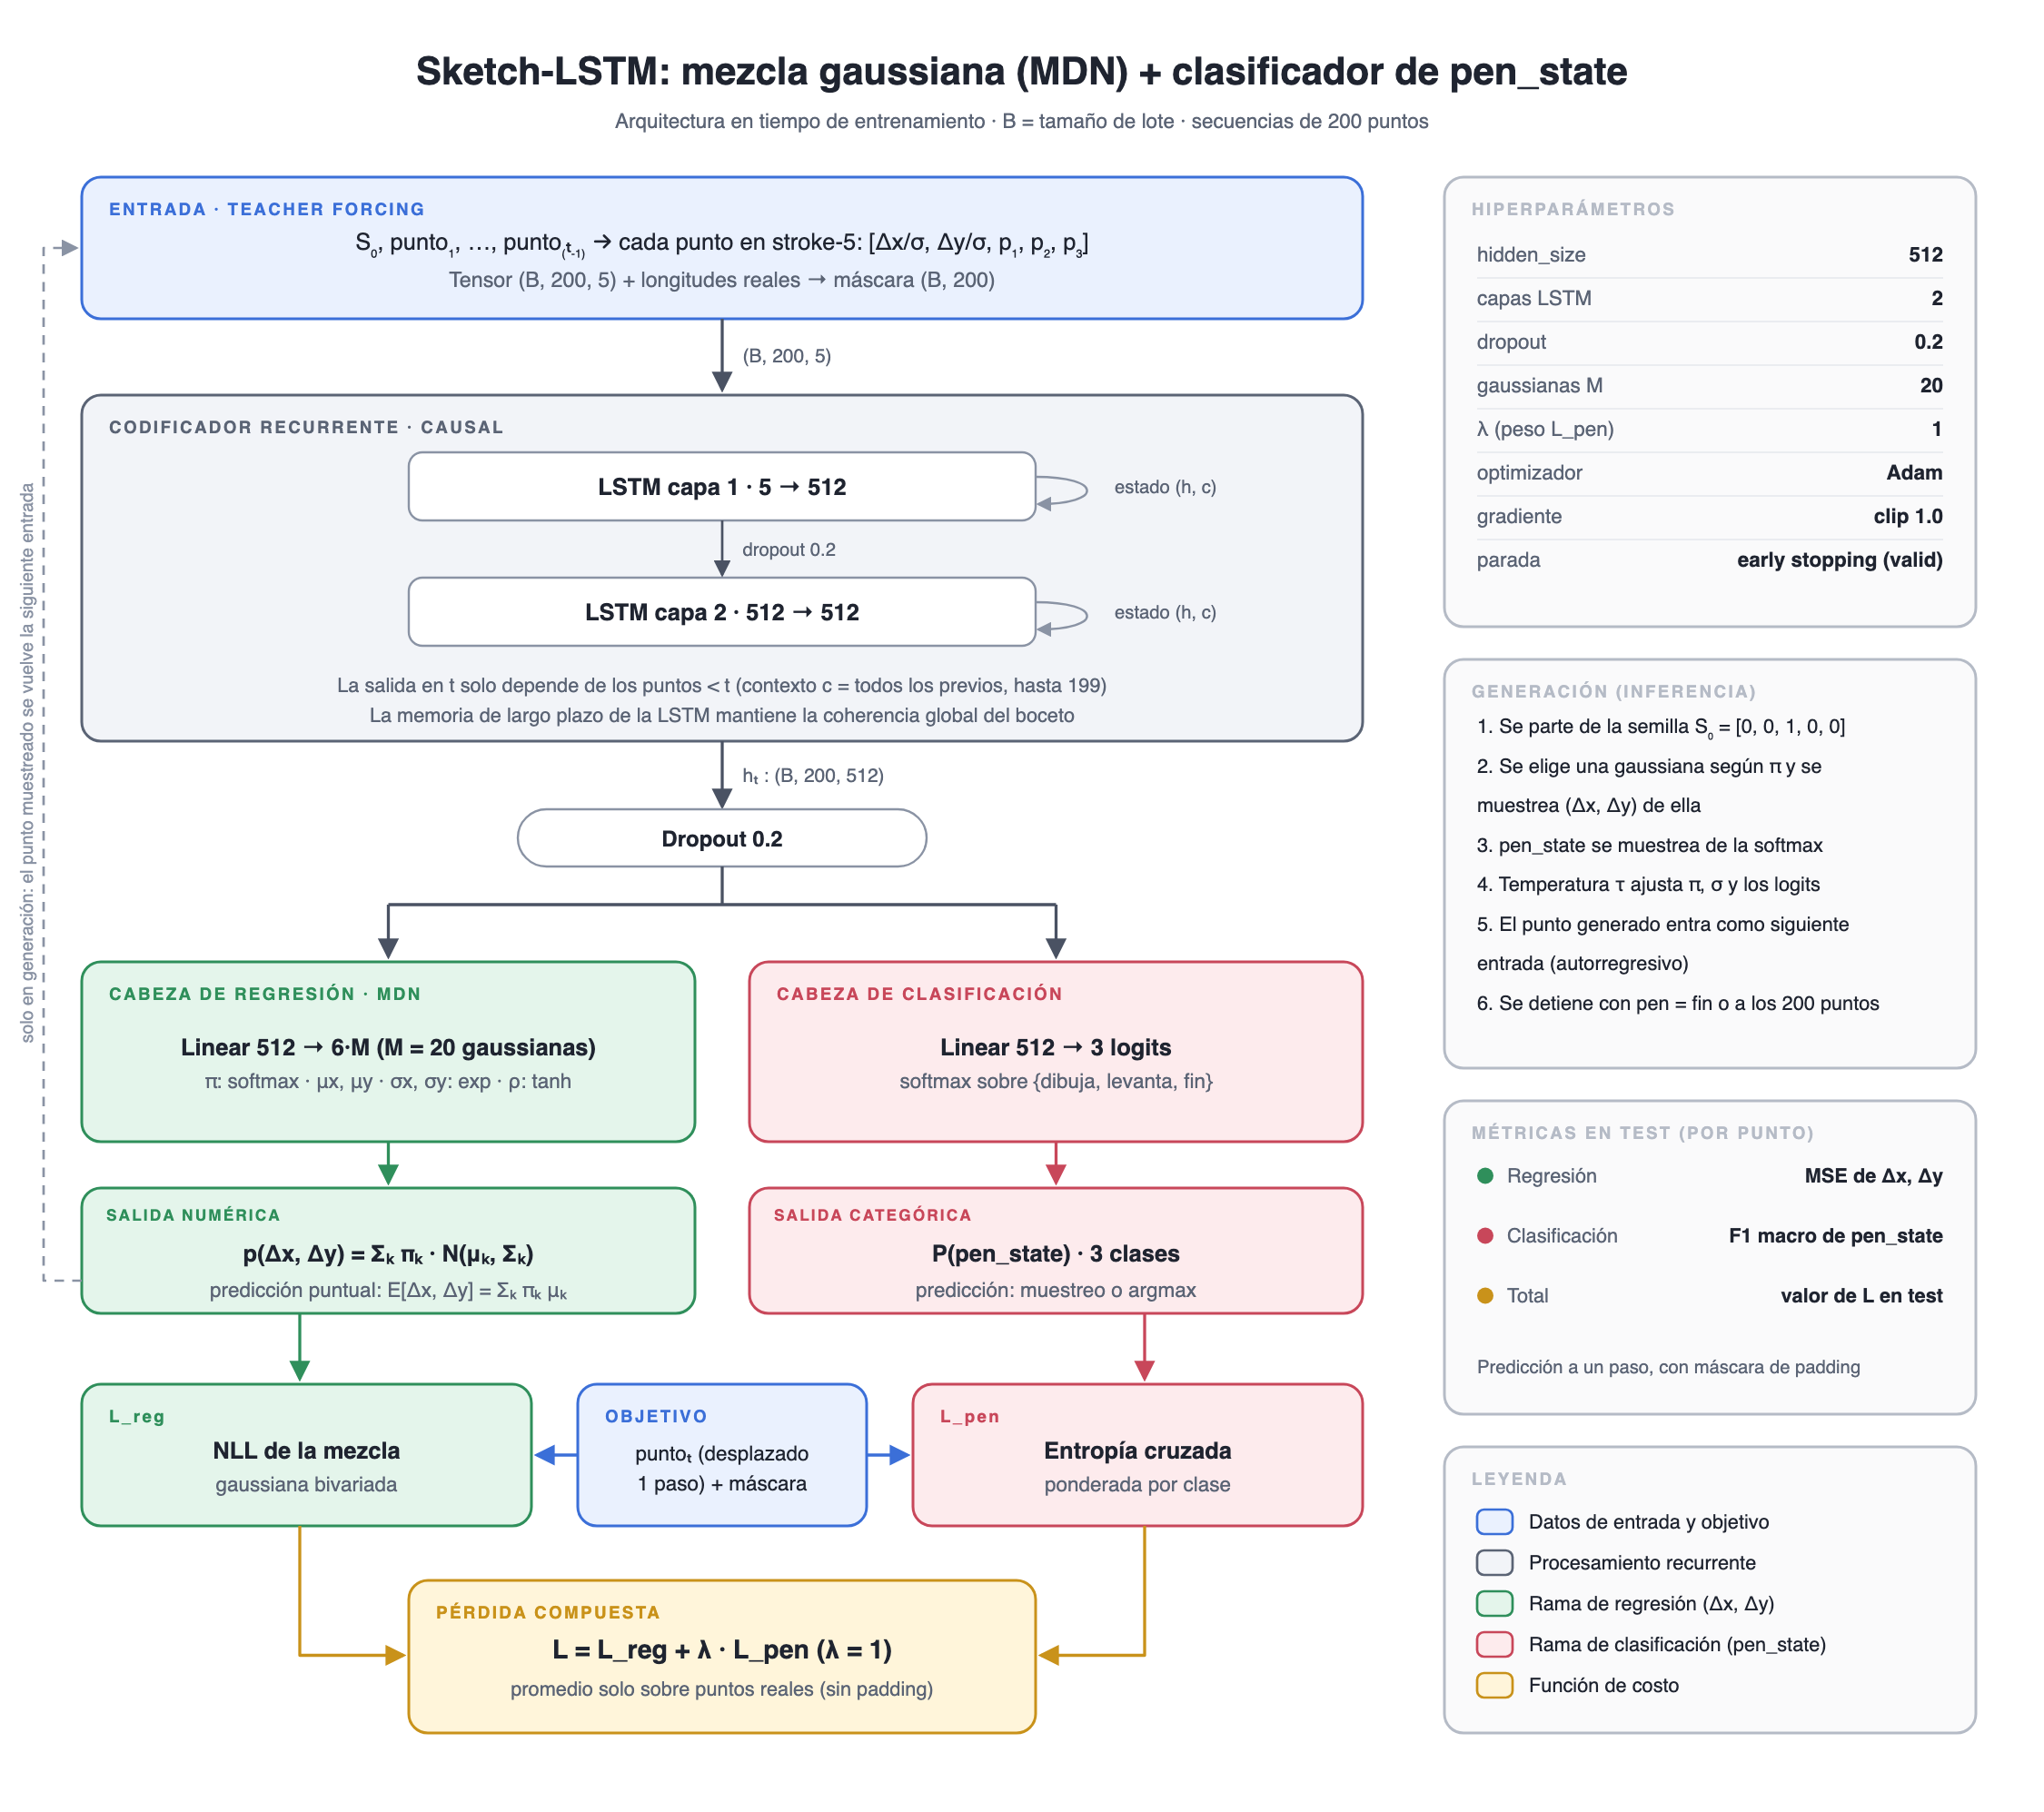

_Fuente vectorial del diagrama: `diagrama_arquitectura.svg` (también entregado por aparte junto con el PNG)._

## Explicación de la arquitectura

1. **Entrada.** Cada punto se representa en formato *stroke-5*: `[Δx/σx, Δy/σy, p1, p2, p3]`, donde Δx y Δy están
   normalizados por su desviación estándar (calculada sólo sobre entrenamiento) y `(p1, p2, p3)` es el *one-hot*
   de `pen_state` (dibuja / levanta el lápiz / fin del dibujo). La secuencia de entrada es
   `[S0, punto_1, …, punto_199]`, donde `S0 = (0, 0, 1, 0, 0)` es un token de inicio, y el objetivo es la misma
   secuencia desplazada un paso: `[punto_1, …, punto_200]` (*teacher forcing*). El lote tiene forma `(B, 200, 5)`
   y viene acompañado de una máscara `(B, 200)` que marca los puntos reales.
2. **Codificador recurrente.** Una **LSTM de 2 capas con 512 unidades** (dropout 0.2 entre capas) recorre la
   secuencia. Por ser causal, el estado oculto en el paso *t* resume **todos** los puntos anteriores
   (contexto *c* = toda la historia, hasta 199 puntos), sin necesidad de fijar una ventana.
3. **Cabeza de regresión (Δx, Δy) — red de densidad de mezcla (MDN).** Una capa `Linear(512 → 6·M)` con
   **M = 20** componentes produce, para cada paso, los parámetros de una mezcla de gaussianas bivariadas:
   pesos π (softmax), medias μx, μy, desviaciones σx, σy (exponencial, para que sean positivas) y correlación ρ
   (tanh, para que esté en (−1, 1)). La salida numérica puntual del modelo es el valor esperado
   E[Δx, Δy] = Σ πk μk, y durante la generación se muestrea de la mezcla.
4. **Cabeza de clasificación (`pen_state`).** Una capa `Linear(512 → 3)` produce los *logits* de los 3 estados.
5. **Pérdida compuesta.** `L = L_reg + λ·L_pen` con λ = 1:
   - `L_reg`: log-verosimilitud negativa (NLL) de (Δx, Δy) reales bajo la mezcla — componente de regresión
     probabilística.
   - `L_pen`: entropía cruzada de `pen_state`, ponderada por clase porque las clases están muy desbalanceadas
     (≈ 90 % "dibuja", ≈ 10 % "levanta", ≈ 1 % "fin").
   - Ambas se promedian **sólo sobre los puntos reales** (máscara).

## Justificación de la selección

- **LSTM y no RNN simple:** los bocetos tienen en promedio ~100 puntos y la forma global (p. ej. cerrar el cuerpo,
  volver a dibujar las patas) depende de lo dibujado muchos pasos atrás. Las compuertas de la LSTM mitigan el
  desvanecimiento del gradiente y retienen esa memoria de largo plazo; es la misma elección del decodificador de
  Sketch-RNN (Ha & Eck, 2017).
- **Mezcla de gaussianas y no un único valor:** el siguiente trazo es **multimodal** (desde un mismo punto el
  dibujante puede ir a la izquierda o a la derecha). Una regresión con MSE aprende la media de esas opciones, lo que
  produce trazos promediados, cortos y que se enrollan; la MDN modela la distribución completa y permite generar
  trazos nítidos muestreando de ella. Además, el valor esperado de la mezcla sigue siendo la predicción óptima en
  MSE, por lo que la métrica obligatoria se calcula sobre la misma salida.
- **Cabeza categórica separada con pesos de clase:** `pen_state` es una variable discreta y el estado "fin" es muy
  poco frecuente; sin ponderación el modelo tendería a no predecirlo nunca (F1 macro bajo y bocetos que no terminan).
- **Tamaño (2×512, ~3,2 M parámetros):** suficiente capacidad para 16.000 secuencias, entrenable en minutos en una GPU,
  y controlado contra el sobreajuste con dropout, aumento de datos (escalado aleatorio), recorte de gradiente,
  *weight decay* y *early stopping* sobre validación.

# 2. Librerías

In [2]:
import os
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from IPython.display import display
from scipy import stats

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Dispositivo de cómputo: GPU (CUDA o Apple MPS) si está disponible, de lo contrario CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.9.1 | dispositivo: mps


# 3. Lectura del dataset y exploración

Se descarga el archivo `.npz` de la categoría `apple` (versión sketch-rnn, ya simplificada con RDP y dividida
en train / valid / test). Cada boceto está en formato *stroke-3*: `(Δx, Δy, pen_lift)`, donde `pen_lift = 1`
indica que el lápiz se levanta después del punto (fin de un trazo).

In [3]:
CATEGORY = "apple"
OUT_DIR = "salidas"
os.makedirs(OUT_DIR, exist_ok=True)

url = f"https://storage.googleapis.com/quickdraw_dataset/sketchrnn/{CATEGORY}.npz"
npz_path = f"{CATEGORY}.npz"
if not os.path.exists(npz_path):
    urllib.request.urlretrieve(url, npz_path)

# En Python 3 se debe cargar con encoding='latin1' y allow_pickle=True
data = np.load(npz_path, encoding="latin1", allow_pickle=True)
raw_train, raw_valid, raw_test = data["train"], data["valid"], data["test"]
print("Tamaños originales -> train:", len(raw_train), "| valid:", len(raw_valid), "| test:", len(raw_test))

sketch = raw_train[0]
print("Forma del primer dibujo:", sketch.shape, "| dtype:", sketch.dtype)
print(sketch[:5])

Tamaños originales -> train: 70000 | valid: 2500 | test: 2500
Forma del primer dibujo: (43, 3) | dtype: int16
[[-17 -18   0]
 [-19 -14   0]
 [-32  -2   0]
 [-13   5   0]
 [-17  11   0]]


Longitud -> media: 37.9 | mediana: 37 | p95: 55 | máx: 62
Bocetos con más de 200 puntos: 0.00%
Δx -> media 0.74, desv. 27.69, rango [-982, 1322]
Δy -> media -1.62, desv. 32.52, rango [-730, 645]
Proporción de puntos con pen_lift = 1 (fin de trazo): 7.2%


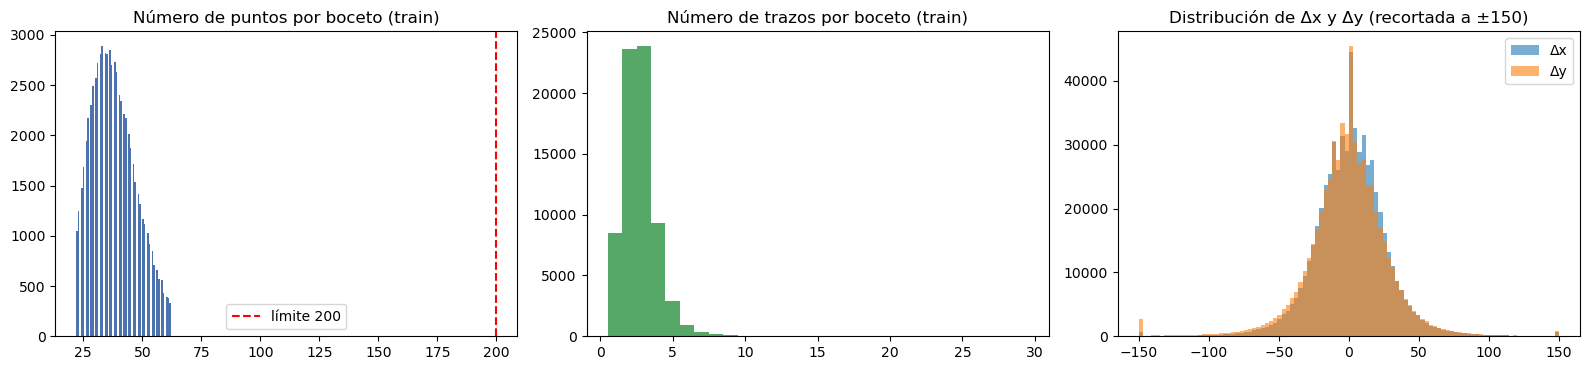

In [4]:
lengths = np.array([len(s) for s in raw_train])
all_pts = np.concatenate(raw_train[:16000]).astype(np.float64)

print(f"Longitud -> media: {lengths.mean():.1f} | mediana: {np.median(lengths):.0f} | "
      f"p95: {np.percentile(lengths, 95):.0f} | máx: {lengths.max()}")
print(f"Bocetos con más de 200 puntos: {(lengths > 200).mean() * 100:.2f}%")
print(f"Δx -> media {all_pts[:, 0].mean():.2f}, desv. {all_pts[:, 0].std():.2f}, rango [{all_pts[:, 0].min():.0f}, {all_pts[:, 0].max():.0f}]")
print(f"Δy -> media {all_pts[:, 1].mean():.2f}, desv. {all_pts[:, 1].std():.2f}, rango [{all_pts[:, 1].min():.0f}, {all_pts[:, 1].max():.0f}]")
print(f"Proporción de puntos con pen_lift = 1 (fin de trazo): {all_pts[:, 2].mean() * 100:.1f}%")

n_strokes = np.array([s[:, 2].sum() for s in raw_train])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(lengths, bins=60, color="#4c72b0")
axes[0].axvline(200, color="red", ls="--", label="límite 200")
axes[0].set_title("Número de puntos por boceto (train)")
axes[0].legend()
axes[1].hist(n_strokes, bins=np.arange(0.5, 30.5), color="#55a868")
axes[1].set_title("Número de trazos por boceto (train)")
axes[2].hist(np.clip(all_pts[:, 0], -150, 150), bins=100, alpha=0.6, label="Δx")
axes[2].hist(np.clip(all_pts[:, 1], -150, 150), bins=100, alpha=0.6, label="Δy")
axes[2].set_title("Distribución de Δx y Δy (recortada a ±150)")
axes[2].legend()
plt.tight_layout()
plt.show()

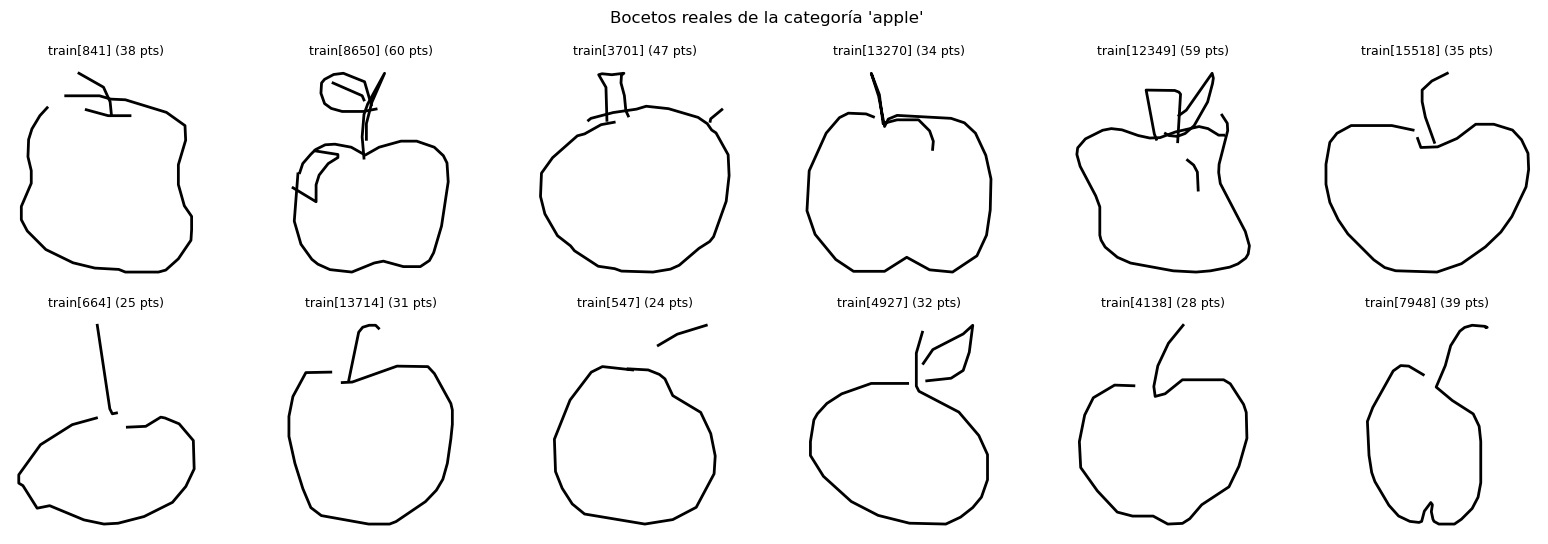

In [5]:
def draw_sketch(ax, sketch, color="black", lw=2):
    """Dibuja un boceto stroke-3 (dx, dy, pen_lift) en unos ejes de matplotlib."""
    sketch = np.asarray(sketch, dtype=np.float64)
    coords = np.cumsum(sketch[:, :2], axis=0)   # desplazamientos relativos -> posiciones absolutas
    start = 0
    for i in range(len(sketch)):
        if sketch[i, 2] == 1 or i == len(sketch) - 1:   # fin de un trazo (o último punto)
            ax.plot(coords[start:i + 1, 0], -coords[start:i + 1, 1], color=color, linewidth=lw)
            start = i + 1
    ax.set_aspect("equal")
    ax.axis("off")


def render_sketch(sketch, filename):
    """Renderiza un boceto stroke-3 y lo guarda como PNG."""
    fig, ax = plt.subplots(figsize=(4, 4))
    draw_sketch(ax, sketch)
    fig.savefig(filename, bbox_inches="tight", dpi=120)
    plt.close(fig)


fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for ax, idx in zip(axes.ravel(), np.random.RandomState(0).choice(16000, 12, replace=False)):
    draw_sketch(ax, raw_train[idx])
    ax.set_title(f"train[{idx}] ({len(raw_train[idx])} pts)", fontsize=9)
plt.suptitle(f"Bocetos reales de la categoría '{CATEGORY}'")
plt.tight_layout()
plt.show()
render_sketch(raw_train[0], os.path.join(OUT_DIR, "ejemplo_real.png"))

## 3.1 Análisis que justifican el diseño del modelo

In [6]:
# Datos de exploración: los 16.000 bocetos de entrenamiento, truncados a 199 puntos reales (como en el modelo)
EDA_N, EDA_MAX = 16_000, 199
eda_sk = [s[:EDA_MAX].astype(np.float64) for s in raw_train[:EDA_N]]
pts = np.concatenate(eda_sk)
sd_x, sd_y = pts[:, 0].std(), pts[:, 1].std()
zx, zy = pts[:, 0] / sd_x, pts[:, 1] / sd_y                                   # Δ normalizados
pos = np.concatenate([np.arange(len(s)) for s in eda_sk])                     # índice del punto en su boceto
n_pts = np.concatenate([np.full(len(s), len(s)) for s in eda_sk])            # longitud del boceto de cada punto
prev_lift = np.concatenate([np.r_[np.nan, s[:-1, 2]] for s in eda_sk])       # pen_lift del punto anterior
lens_eda = np.array([len(s) for s in eda_sk])
strokes_eda = np.array([s[:, 2].sum() for s in eda_sk])
print(f"{len(eda_sk):,} bocetos | {len(pts):,} puntos | σx = {sd_x:.2f} px | σy = {sd_y:.2f} px")

16,000 bocetos | 607,404 puntos | σx = 27.69 px | σy = 32.52 px


### a) Dos regímenes de movimiento y colas pesadas

Se compara la distribución de (Δx, Δy) en dos situaciones: **dentro de un trazo** (el punto anterior seguía en el
papel) y en el **primer punto después de levantar el lápiz** (el salto hacia donde empieza el trazo siguiente). Si los
dos regímenes tienen escalas muy distintas, una única gaussiana, o una regresión con MSE que sólo aprende la media,
no puede describir ambos a la vez. Una **mezcla de gaussianas** sí puede: dedica componentes estrechas a los
movimientos cortos dentro de los trazos y componentes anchas a los saltos entre trazos.

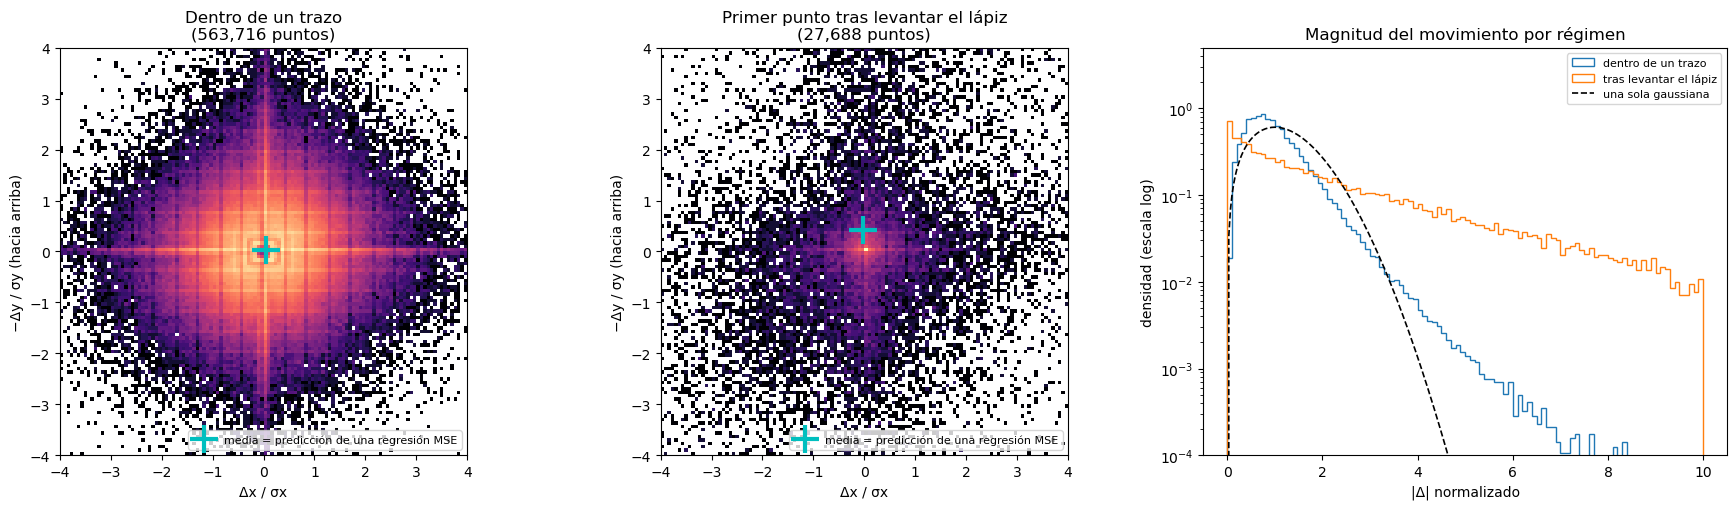

dentro de un trazo      :  92.8 % de los puntos | varianza media de Δ normalizado = 0.75
tras levantar el lápiz  :   4.6 % de los puntos | varianza media de Δ normalizado = 6.16
Los saltos tras levantar el lápiz son 4.7 % de los puntos pero aportan 28.7 % del error cuadrático de una predicción constante.


In [7]:
mid = prev_lift == 0     # continuación de un trazo
after = prev_lift == 1   # primer punto tras levantar el lápiz
LIM = 4

fig = plt.figure(figsize=(18, 5.2))
for i, (m, title) in enumerate([(mid, "Dentro de un trazo"), (after, "Primer punto tras levantar el lápiz")]):
    ax = fig.add_subplot(1, 3, i + 1)
    ax.hist2d(zx[m], -zy[m], bins=120, range=[[-LIM, LIM], [-LIM, LIM]], cmap="magma", norm=LogNorm())
    ax.plot(zx[m].mean(), -zy[m].mean(), "c+", ms=20, mew=3, label="media = predicción de una regresión MSE")
    ax.set_title(f"{title}\n({m.sum():,} puntos)")
    ax.set_xlabel("Δx / σx"); ax.set_ylabel("−Δy / σy (hacia arriba)"); ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=8)
ax = fig.add_subplot(1, 3, 3)
grid = np.linspace(0, 10, 300)
r_all = np.hypot(zx, zy)
for m, label in [(mid, "dentro de un trazo"), (after, "tras levantar el lápiz")]:
    ax.hist(np.hypot(zx[m], zy[m]), bins=100, range=(0, 10), density=True, histtype="step", lw=2, label=label)
sigma_all = np.sqrt((r_all ** 2).mean() / 2)                     # una sola gaussiana isotrópica para todos los puntos
ax.plot(grid, stats.rayleigh.pdf(grid, scale=sigma_all), "k--", lw=1.2, label="una sola gaussiana")
ax.set_yscale("log"); ax.set_ylim(1e-4, 5)
ax.set_xlabel("|Δ| normalizado"); ax.set_ylabel("densidad (escala log)")
ax.set_title("Magnitud del movimiento por régimen")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Cuánto del error cuadrático de una predicción constante (la media de cada grupo) aportan los saltos entre trazos
for m, label in [(mid, "dentro de un trazo"), (after, "tras levantar el lápiz")]:
    var = ((zx[m] - zx[m].mean()) ** 2 + (zy[m] - zy[m].mean()) ** 2).mean() / 2
    print(f"{label:<24}: {m.mean() * 100:5.1f} % de los puntos | varianza media de Δ normalizado = {var:.2f}")
sq_mid = (((zx[mid] - zx[mid].mean()) ** 2) + ((zy[mid] - zy[mid].mean()) ** 2)).sum()
sq_after = (((zx[after] - zx[after].mean()) ** 2) + ((zy[after] - zy[after].mean()) ** 2)).sum()
print(f"Los saltos tras levantar el lápiz son {after.sum() / (mid.sum() + after.sum()) * 100:.1f} % de los puntos "
      f"pero aportan {sq_after / (sq_mid + sq_after) * 100:.1f} % del error cuadrático de una predicción constante.")

### b) Colas pesadas y valores atípicos de Δ 

Una distribución normal tiene curtosis en exceso 0 y prácticamente ningún valor más allá de 5σ. Se cuantifica qué
tan lejos están Δx y Δy de ese comportamiento y cuántos saltos extremos hay. Sketch-RNN original recorta los
desplazamientos a ±1000 px; aquí sólo se reporta, sin filtrar (el límite de 16.000 bocetos se respeta tal cual).

,desv. est. (px),mediana |Δ| (px),p99 |Δ| (px),p99.9 |Δ| (px),máx |Δ| (px),máx |Δ| (en σ),curtosis en exceso,% |Δ| > 5σ,% |Δ| > 10σ
Δx,27.69,15.00,90.00,183.00,1322.00,47.75,31.70,0.25,0.02
Δy,32.52,15.00,114.00,273.00,730.00,22.45,21.69,0.48,0.04


Bocetos con algún desplazamiento > 1000 px (recorte de Sketch-RNN): 1 de 16,000


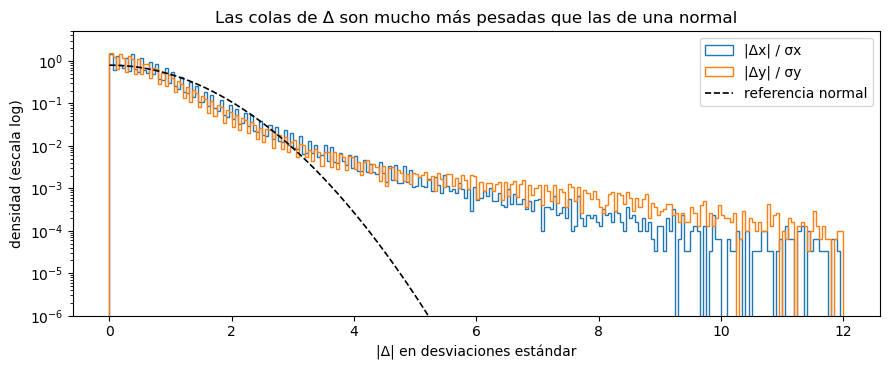

In [8]:
rows = {}
for name, d, sd in [("Δx", pts[:, 0], sd_x), ("Δy", pts[:, 1], sd_y)]:
    a = np.abs(d)
    rows[name] = {
        "desv. est. (px)": sd, "mediana |Δ| (px)": np.median(a), "p99 |Δ| (px)": np.percentile(a, 99),
        "p99.9 |Δ| (px)": np.percentile(a, 99.9), "máx |Δ| (px)": a.max(), "máx |Δ| (en σ)": a.max() / sd,
        "curtosis en exceso": stats.kurtosis(d), "% |Δ| > 5σ": (a > 5 * sd).mean() * 100,
        "% |Δ| > 10σ": (a > 10 * sd).mean() * 100,
    }
display(pd.DataFrame(rows).T.style.format("{:.2f}").set_caption("Colas de la distribución de Δ (entrenamiento)"))
n_big = sum(np.abs(s[:, :2]).max() > 1000 for s in eda_sk)
print(f"Bocetos con algún desplazamiento > 1000 px (recorte de Sketch-RNN): {n_big} de {EDA_N:,}")

fig, ax = plt.subplots(figsize=(9, 3.8))
grid = np.linspace(0, 12, 300)
ax.hist(np.abs(zx), bins=240, range=(0, 12), density=True, histtype="step", lw=1.8, label="|Δx| / σx")
ax.hist(np.abs(zy), bins=240, range=(0, 12), density=True, histtype="step", lw=1.8, label="|Δy| / σy")
ax.plot(grid, 2 * stats.norm.pdf(grid), "k--", lw=1.2, label="referencia normal")
ax.set_yscale("log"); ax.set_ylim(1e-6, 5)
ax.set_xlabel("|Δ| en desviaciones estándar"); ax.set_ylabel("densidad (escala log)")
ax.set_title("Las colas de Δ son mucho más pesadas que las de una normal")
ax.legend()
plt.tight_layout()
plt.show()

### c) Autocorrelación de Δ a lo largo del boceto 

Correlación entre el desplazamiento del punto *t* y el del punto *t − k*, juntando los pares de todos los bocetos.
Si los puntos consecutivos se parecen y la correlación decae lentamente, el pasado contiene información útil para
predecir el siguiente punto: es la justificación de usar una **LSTM con toda la historia como contexto**. Como
referencia se calcula lo mismo con el orden de los puntos barajado dentro de cada boceto (sin estructura temporal).

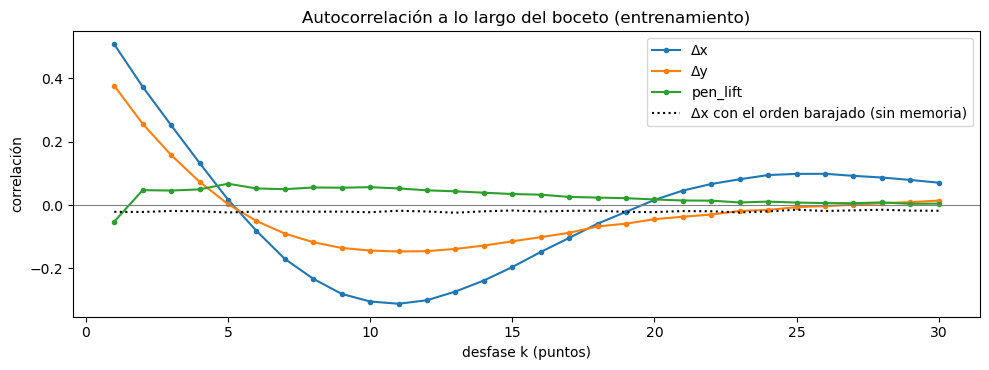

Δx        correlación con k=1: +0.507 | k=5: +0.017 | |r| < 0.1 desde k = 5
Δy        correlación con k=1: +0.377 | k=5: +0.003 | |r| < 0.1 desde k = 4
pen_lift  correlación con k=1: -0.052 | k=5: +0.067 | |r| < 0.1 desde k = 1


In [9]:
def pooled_autocorr(sketches, col, max_lag=30):
    # Correlación entre el valor en t y en t - k, juntando los pares de todas las secuencias
    out = []
    for k in range(1, max_lag + 1):
        a = np.concatenate([s[:-k, col] for s in sketches if len(s) > k])
        b = np.concatenate([s[k:, col] for s in sketches if len(s) > k])
        out.append(np.corrcoef(a, b)[0, 1])
    return np.array(out)


MAX_LAG = 30
lags = np.arange(1, MAX_LAG + 1)
rng_eda = np.random.RandomState(0)
shuffled = [s[rng_eda.permutation(len(s))] for s in eda_sk]
acf = {"Δx": pooled_autocorr(eda_sk, 0, MAX_LAG), "Δy": pooled_autocorr(eda_sk, 1, MAX_LAG),
       "pen_lift": pooled_autocorr(eda_sk, 2, MAX_LAG)}
acf_shuffled = pooled_autocorr(shuffled, 0, MAX_LAG)

fig, ax = plt.subplots(figsize=(10, 3.8))
for name, values in acf.items():
    ax.plot(lags, values, "o-", ms=3, label=name)
ax.plot(lags, acf_shuffled, "k:", label="Δx con el orden barajado (sin memoria)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("desfase k (puntos)"); ax.set_ylabel("correlación")
ax.set_title("Autocorrelación a lo largo del boceto (entrenamiento)")
ax.legend()
plt.tight_layout()
plt.show()
for name, values in acf.items():
    below = np.where(np.abs(values) < 0.1)[0]
    first = lags[below[0]] if len(below) else f"> {MAX_LAG}"
    print(f"{name:<9} correlación con k=1: {values[0]:+.3f} | k=5: {values[4]:+.3f} | |r| < 0.1 desde k = {first}")

### d) `pen_state` según la posición en el boceto 

La frecuencia global de cada estado (calculada como en el modelo, incluyendo el punto de fin) oculta que los estados
no se distribuyen de forma uniforme. Se muestra (i) la probabilidad de **levantar el lápiz** según la posición relativa
en el boceto, (ii) la **tasa de fin**: la probabilidad de que el dibujo termine en la posición *t* dado que llegó hasta
ahí, que es lo que el modelo debe aprender sin conocer la longitud total, y (iii) la frecuencia de cada clase junto
con los pesos ∝ 1/√frecuencia que usa la pérdida.

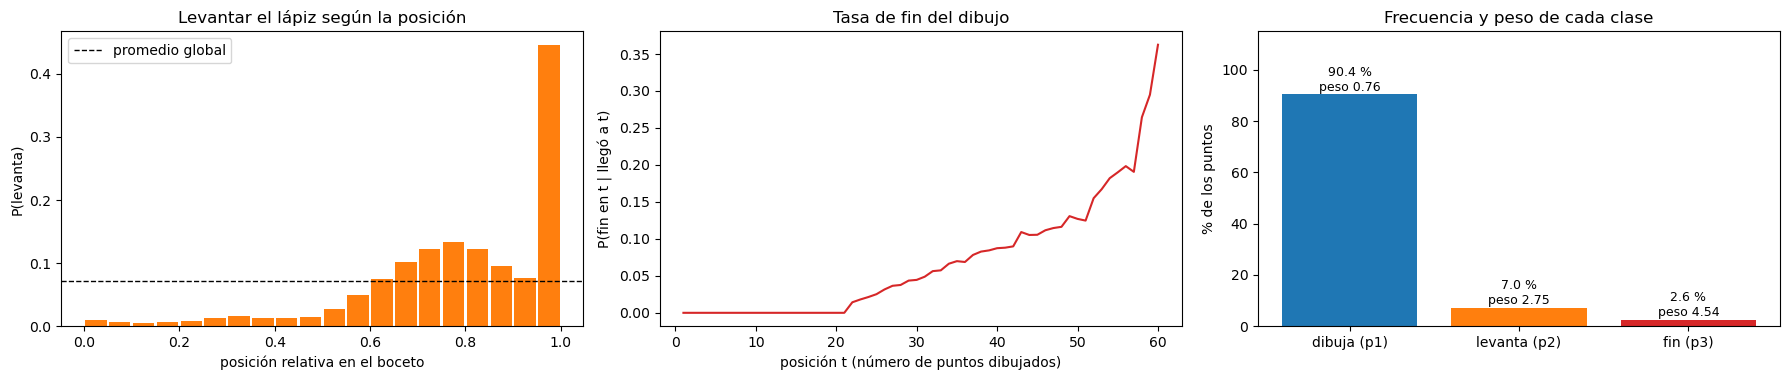

P(levanta) en el primer 10 % del boceto: 0.008 | en el último 10 %: 0.261
Tasa de fin máxima: 0.363 en t = 60 | mediana de la longitud: 37 puntos


In [10]:
rel = pos / np.maximum(n_pts - 1, 1)
edges = np.linspace(0, 1, 21)
b_idx = np.clip(np.digitize(rel, edges) - 1, 0, 19)
p_lift_rel = np.array([pts[b_idx == b, 2].mean() for b in range(20)])

# Tasa de fin: el punto de fin ocupa la posición n (tras n puntos reales)
T_MAX = min(int(np.percentile(lens_eda, 99)), EDA_MAX - 1)   # se excluye t = 199 (bocetos truncados)
t_axis = np.arange(1, T_MAX + 1)
hazard = np.array([(lens_eda == t).sum() / max((lens_eda >= t).sum(), 1) for t in t_axis])

n_p2 = pts[:, 2].sum()
counts = np.array([len(pts) - n_p2, n_p2, len(eda_sk)])
freq = counts / counts.sum()
weights = freq ** -0.5
weights = weights / (freq * weights).sum()

fig, axes = plt.subplots(1, 3, figsize=(18, 3.9))
axes[0].bar((edges[:-1] + edges[1:]) / 2, p_lift_rel, width=0.045, color="C1")
axes[0].axhline(pts[:, 2].mean(), color="k", ls="--", lw=1, label="promedio global")
axes[0].set_xlabel("posición relativa en el boceto"); axes[0].set_ylabel("P(levanta)")
axes[0].set_title("Levantar el lápiz según la posición"); axes[0].legend()
axes[1].plot(t_axis, hazard, color="C3")
axes[1].set_xlabel("posición t (número de puntos dibujados)"); axes[1].set_ylabel("P(fin en t | llegó a t)")
axes[1].set_title("Tasa de fin del dibujo")
labels_pen = ["dibuja (p1)", "levanta (p2)", "fin (p3)"]
axes[2].bar(labels_pen, freq * 100, color=["C0", "C1", "C3"])
for i, (f, w) in enumerate(zip(freq, weights)):
    axes[2].text(i, f * 100 + 1.5, f"{f * 100:.1f} %\npeso {w:.2f}", ha="center", fontsize=9)
axes[2].set_ylim(0, 115); axes[2].set_ylabel("% de los puntos")
axes[2].set_title("Frecuencia y peso de cada clase")
plt.tight_layout()
plt.show()
print(f"P(levanta) en el primer 10 % del boceto: {p_lift_rel[:2].mean():.3f} | en el último 10 %: {p_lift_rel[-2:].mean():.3f}")
print(f"Tasa de fin máxima: {hazard.max():.3f} en t = {t_axis[hazard.argmax()]} | "
      f"mediana de la longitud: {np.median(lens_eda):.0f} puntos")

## 3.2 Calidad de los datos

Se buscan bocetos degenerados, duplicados y diferencias entre los conjuntos de entrenamiento, validación y prueba.
Todo se **reporta sin filtrar**: el split obligatorio se usa tal como viene en el `.npz`.

### a) Bocetos degenerados

,bocetos,%
menos de 5 puntos,0,0.00
un solo trazo,"1,957",12.23
caja < 10 % de la mediana,0,0.00
algún salto > 10σ,329,2.06
al menos uno,"2,284",14.27


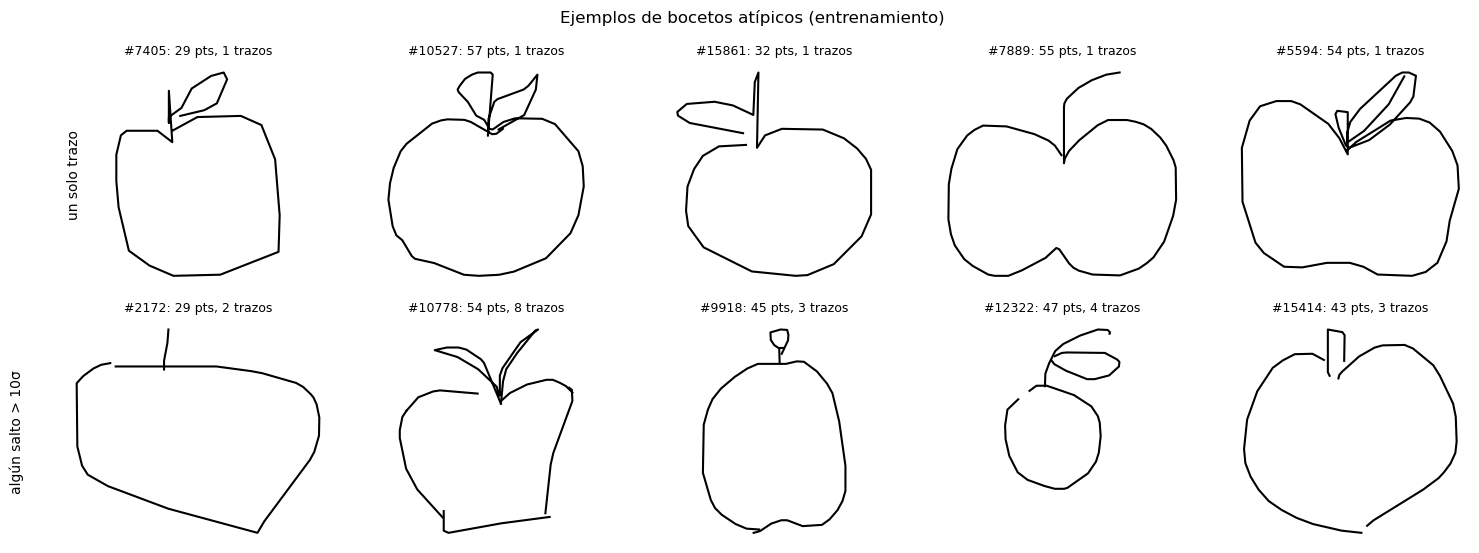

In [11]:
def abs_coords(s):
    return np.cumsum(s[:, :2], axis=0)


bbox_wh = np.array([np.ptp(abs_coords(s), axis=0) for s in eda_sk])     # ancho y alto de la caja (px)
side = bbox_wh.max(axis=1)
max_jump = np.array([np.max(np.abs(s[:, :2]) / [sd_x, sd_y]) for s in eda_sk])

flags = {
    "menos de 5 puntos": lens_eda < 5,
    "un solo trazo": strokes_eda <= 1,
    "caja < 10 % de la mediana": side < 0.1 * np.median(side),
    "algún salto > 10σ": max_jump > 10,
}
flag_table = pd.DataFrame({"bocetos": {k: int(v.sum()) for k, v in flags.items()},
                           "%": {k: v.mean() * 100 for k, v in flags.items()}})
any_flag = np.any(np.stack(list(flags.values())), axis=0)
flag_table.loc["al menos uno"] = [int(any_flag.sum()), any_flag.mean() * 100]
display(flag_table.style.format({"bocetos": "{:,.0f}", "%": "{:.2f}"}).set_caption("Bocetos atípicos en entrenamiento"))

rng_eda = np.random.RandomState(1)
shown = {k: v for k, v in flags.items() if v.any()}           # sólo los criterios con algún caso
fig, axes = plt.subplots(len(shown), 5, figsize=(15, 2.8 * len(shown)), squeeze=False)
for row, (name, m) in zip(axes, shown.items()):
    ids = np.where(m)[0]
    chosen = rng_eda.choice(ids, min(5, len(ids)), replace=False) if len(ids) else []
    for j, ax in enumerate(row):
        ax.axis("off")
        if j < len(chosen):
            k = chosen[j]
            draw_sketch(ax, eda_sk[k], lw=1.5)
            ax.set_title(f"#{k}: {lens_eda[k]} pts, {int(strokes_eda[k])} trazos", fontsize=9)
    row[0].text(-0.15, 0.5, name, transform=row[0].transAxes, rotation=90, ha="right", va="center", fontsize=10)
plt.suptitle("Ejemplos de bocetos atípicos (entrenamiento)")
plt.tight_layout()
plt.show()

### b) Duplicados

Un boceto repetido entre entrenamiento y prueba inflaría las métricas de prueba. Se buscan duplicados **exactos** y
**casi idénticos** (mismo número de puntos, mismos estados del lápiz y posiciones absolutas iguales en una cuadrícula
de 8 px).

In [12]:
def key_exact(s):
    return np.asarray(s[:EDA_MAX], dtype=np.int32).tobytes()


def key_near(s, grid=8):
    s = np.asarray(s[:EDA_MAX], dtype=np.float64)
    c = abs_coords(s)
    c = c - c.min(axis=0)
    return np.round(c / grid).astype(np.int32).tobytes() + s[:, 2].astype(np.int8).tobytes()


split_sets = {"train": raw_train[:16_000], "valid": raw_valid[:2_000], "test": raw_test[:2_000]}
dup_rows = {}
for kind, fn in [("exactos", key_exact), ("casi idénticos", key_near)]:
    keys = {name: [fn(s) for s in sk] for name, sk in split_sets.items()}
    row = {f"dentro de {n}": len(k) - len(set(k)) for n, k in keys.items()}
    for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
        sb = set(keys[b])
        row[f"{a} ∩ {b}"] = sum(k in sb for k in set(keys[a]))
    dup_rows[kind] = row
display(pd.DataFrame(dup_rows).T.style.set_caption("Bocetos duplicados (número de bocetos repetidos)"))

,dentro de train,dentro de valid,dentro de test,train ∩ valid,train ∩ test,valid ∩ test
exactos,0,0,0,0,0,0
casi idénticos,0,0,0,0,0,0


### c) Comparación entre entrenamiento, validación y prueba

Se comparan las distribuciones de longitud, número de trazos, tamaño medio de los desplazamientos y relación de
aspecto en los tres conjuntos del split obligatorio. El estadístico **D de Kolmogorov–Smirnov** mide la máxima
diferencia entre las distribuciones acumuladas (0 = idénticas); con 2.000 bocetos, valores de D < 0.05 indican
distribuciones prácticamente iguales.

,longitud (puntos),trazos,|Δ| medio (px),aspecto (ancho/alto),D KS longitud,D KS trazos,D KS |Δ|,D KS aspecto
train,37.963,2.731,31.952,0.884,—,—,—,—
valid,38.102,2.683,31.875,0.886,0.013,0.016,0.012,0.028
test,37.913,2.727,31.835,0.882,0.008,0.012,0.024,0.017


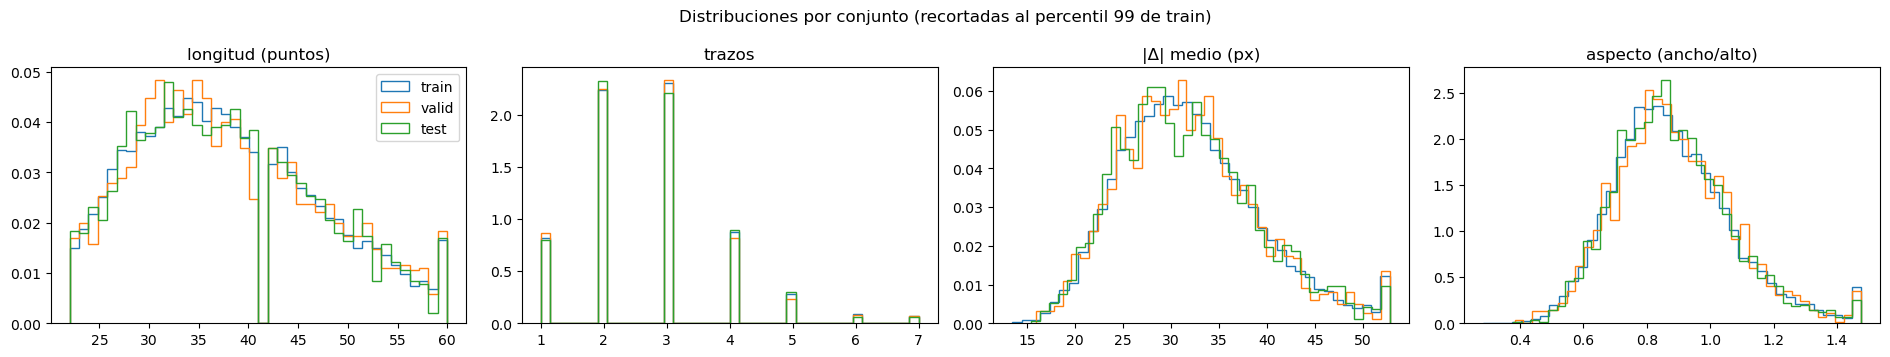

In [13]:
def sketch_features(sk):
    sk = [np.asarray(s[:EDA_MAX], dtype=np.float64) for s in sk]
    wh = np.array([np.ptp(abs_coords(s), axis=0) for s in sk])
    return pd.DataFrame({
        "longitud (puntos)": [len(s) for s in sk],
        "trazos": [s[:, 2].sum() for s in sk],
        "|Δ| medio (px)": [np.hypot(s[:, 0], s[:, 1]).mean() for s in sk],
        "aspecto (ancho/alto)": wh[:, 0] / np.maximum(wh[:, 1], 1),
    })


feats = {name: sketch_features(sk) for name, sk in split_sets.items()}
summary = pd.DataFrame({name: f.mean() for name, f in feats.items()}).T
for col in feats["train"].columns:
    for name in ["valid", "test"]:
        summary.loc[name, f"D KS {col.split(' ')[0]}"] = stats.ks_2samp(feats["train"][col], feats[name][col]).statistic
display(summary.style.format("{:.3f}", na_rep="—").set_caption("Medias por conjunto y estadístico D de KS frente a train"))

fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, col in zip(axes, feats["train"].columns):
    hi = np.percentile(feats["train"][col], 99)
    for name, f in feats.items():
        ax.hist(np.clip(f[col], None, hi), bins=40, density=True, histtype="step", lw=1.8, label=name)
    ax.set_title(col)
axes[0].legend()
plt.suptitle("Distribuciones por conjunto (recortadas al percentil 99 de train)")
plt.tight_layout()
plt.show()

## 3.3 Estructura del dibujo

### a) Tamaño y proporción de los bocetos → rango del aumento de datos

El aumento de datos del entrenamiento escala Δx y Δy por factores independientes en [0.85, 1.15], lo que cambia la
relación de aspecto hasta ×1.35. Se compara ese rango con la variación natural del tamaño y de la proporción de los
bocetos.

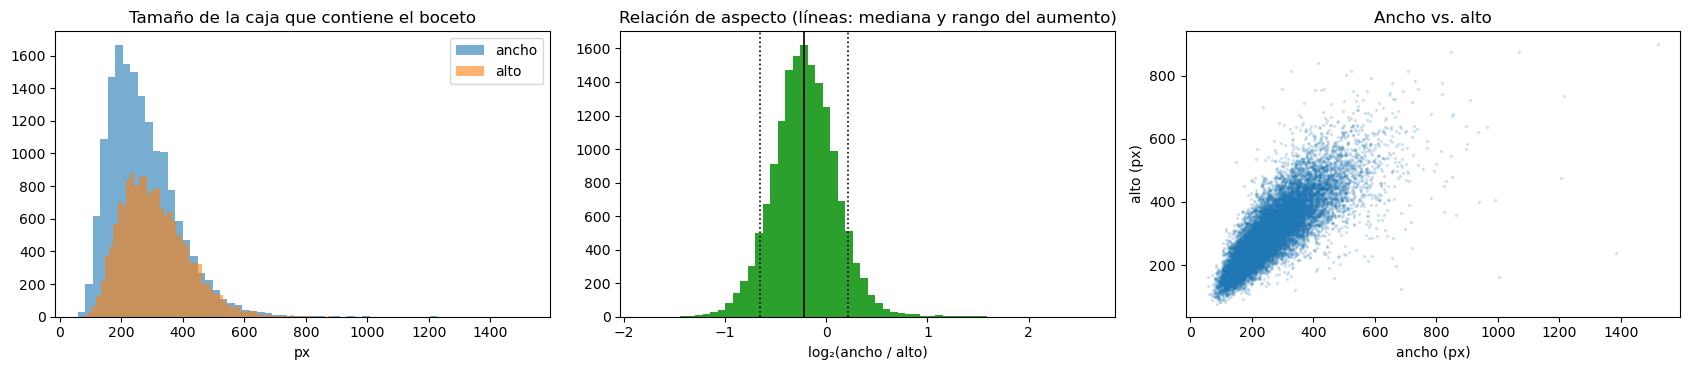

Ancho mediano 251 px | alto mediano 293 px
Aspecto: mediana 0.86, rango intercuartílico [0.75, 0.99] (cociente p75/p25 = 1.32); el aumento de datos lo cambia como máximo ×1.35


In [14]:
width, height = bbox_wh[:, 0], bbox_wh[:, 1]
aspect = width / np.maximum(height, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(width, bins=60, alpha=0.6, label="ancho"); axes[0].hist(height, bins=60, alpha=0.6, label="alto")
axes[0].set_xlabel("px"); axes[0].set_title("Tamaño de la caja que contiene el boceto"); axes[0].legend()
axes[1].hist(np.log2(aspect), bins=60, color="C2")
for f, ls in [(0.85 / 1.15, ":"), (1.15 / 0.85, ":")]:
    axes[1].axvline(np.log2(np.median(aspect) * f), color="k", ls=ls, lw=1.2)
axes[1].axvline(np.log2(np.median(aspect)), color="k", lw=1.2)
axes[1].set_xlabel("log₂(ancho / alto)")
axes[1].set_title("Relación de aspecto (líneas: mediana y rango del aumento)")
axes[2].scatter(width, height, s=2, alpha=0.15)
axes[2].set_xlabel("ancho (px)"); axes[2].set_ylabel("alto (px)"); axes[2].set_title("Ancho vs. alto")
plt.tight_layout()
plt.show()
q25, q50, q75 = np.percentile(aspect, [25, 50, 75])
print(f"Ancho mediano {np.median(width):.0f} px | alto mediano {np.median(height):.0f} px")
print(f"Aspecto: mediana {q50:.2f}, rango intercuartílico [{q25:.2f}, {q75:.2f}] (cociente p75/p25 = {q75 / q25:.2f}); "
      f"el aumento de datos lo cambia como máximo ×{1.15 / 0.85:.2f}")

### b) Puntos por trazo y orden de los trazos

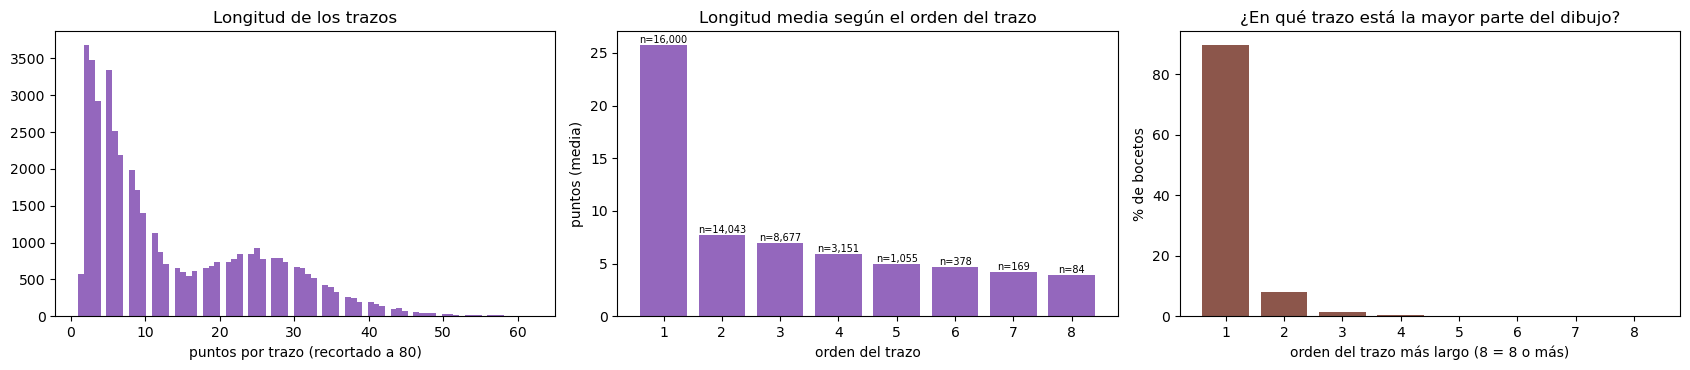

Trazos por boceto: mediana 3 | puntos por trazo: mediana 9
El primer trazo contiene en mediana el 72 % de los puntos del boceto, y es el más largo en el 90 % de los bocetos.


In [15]:
def split_strokes(s):
    return [st for st in np.split(s, np.where(s[:, 2] == 1)[0] + 1) if len(st)]


strokes_per_sketch = [split_strokes(s) for s in eda_sk]
stroke_len = np.concatenate([[len(st) for st in sts] for sts in strokes_per_sketch])
MAX_ORDER = 8
order_len = [[len(sts[i]) for sts in strokes_per_sketch if len(sts) > i] for i in range(MAX_ORDER)]
longest_order = np.array([int(np.argmax([len(st) for st in sts])) + 1 for sts in strokes_per_sketch])
first_share = np.array([len(sts[0]) / sum(len(st) for st in sts) for sts in strokes_per_sketch])

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(np.clip(stroke_len, None, 80), bins=80, color="C4")
axes[0].set_xlabel("puntos por trazo (recortado a 80)"); axes[0].set_title("Longitud de los trazos")
axes[1].bar(range(1, MAX_ORDER + 1), [np.mean(o) for o in order_len], color="C4")
for i, o in enumerate(order_len):
    axes[1].text(i + 1, np.mean(o), f"n={len(o):,}", ha="center", va="bottom", fontsize=7)
axes[1].set_xlabel("orden del trazo"); axes[1].set_ylabel("puntos (media)")
axes[1].set_title("Longitud media según el orden del trazo")
vals, cnts = np.unique(np.clip(longest_order, 1, MAX_ORDER), return_counts=True)
axes[2].bar(vals, cnts / len(longest_order) * 100, color="C5")
axes[2].set_xlabel(f"orden del trazo más largo ({MAX_ORDER} = {MAX_ORDER} o más)"); axes[2].set_ylabel("% de bocetos")
axes[2].set_title("¿En qué trazo está la mayor parte del dibujo?")
plt.tight_layout()
plt.show()
print(f"Trazos por boceto: mediana {np.median([len(s) for s in strokes_per_sketch]):.0f} | "
      f"puntos por trazo: mediana {np.median(stroke_len):.0f}")
print(f"El primer trazo contiene en mediana el {np.median(first_share) * 100:.0f} % de los puntos del boceto, "
      f"y es el más largo en el {(longest_order == 1).mean() * 100:.0f} % de los bocetos.")

### c) Mapa de calor de la tinta y punto de inicio

Cada boceto se centra en su caja y se escala para que su lado mayor mida 1. Luego se muestrean puntos a lo largo de
los trazos dibujados, para que los tramos rectos (con pocos puntos tras la simplificación RDP) pesen igual que las
curvas. El mapa resume la **forma típica** de la categoría y dónde suele **empezar** el dibujo.

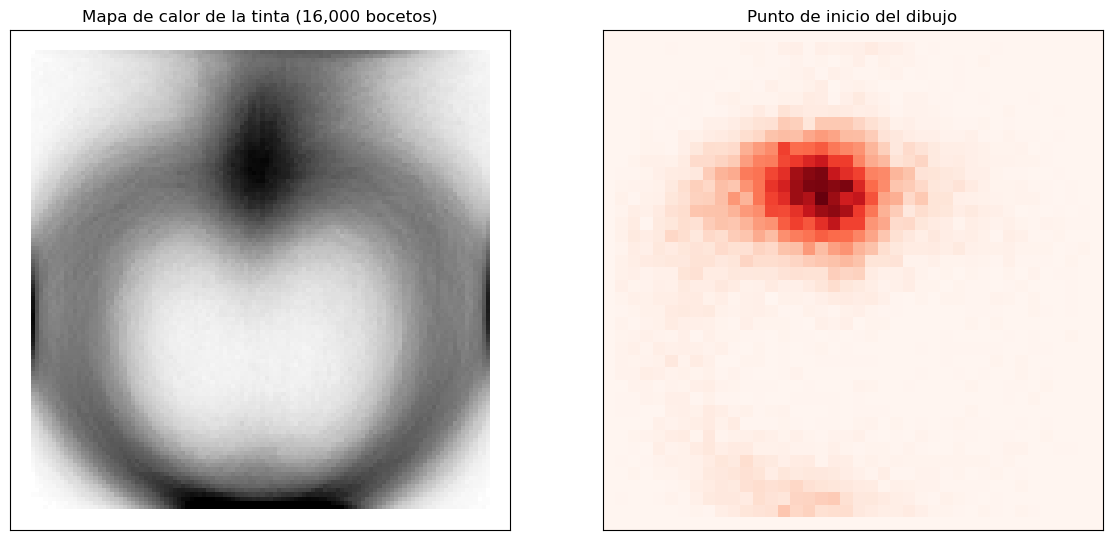

In [16]:
def normalized_ink(s, step=0.01):
    # Puntos equiespaciados sobre los trazos de un boceto normalizado a su caja (lado mayor = 1)
    c = abs_coords(s)
    center = (c.max(axis=0) + c.min(axis=0)) / 2
    scale = max(np.ptp(c, axis=0).max(), 1e-6)
    c = (c - center) / scale
    out = []
    for idx in np.split(np.arange(len(s)), np.where(s[:, 2] == 1)[0] + 1):
        if len(idx) < 2:
            continue
        p = c[idx]
        arc = np.r_[0, np.cumsum(np.hypot(*np.diff(p, axis=0).T))]
        t = np.arange(0, arc[-1] + step, step)
        out.append(np.c_[np.interp(t, arc, p[:, 0]), np.interp(t, arc, p[:, 1])])
    return (np.vstack(out) if out else np.empty((0, 2))), c[0]


ink, starts = zip(*(normalized_ink(s) for s in eda_sk))
ink, starts = np.vstack(ink), np.array(starts)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
H, _, _ = np.histogram2d(-ink[:, 1], ink[:, 0], bins=120, range=[[-0.55, 0.55], [-0.55, 0.55]])
H = np.sqrt(H)                                                  # raíz cuadrada para ver zonas de poca y mucha tinta
axes[0].imshow(H, origin="lower", extent=[-0.55, 0.55, -0.55, 0.55], cmap="Greys", vmax=np.percentile(H, 99.5))
axes[0].set_title(f"Mapa de calor de la tinta ({EDA_N:,} bocetos)")
axes[1].hist2d(starts[:, 0], -starts[:, 1], bins=40, range=[[-0.55, 0.55], [-0.55, 0.55]], cmap="Reds")
axes[1].set_title("Punto de inicio del dibujo")
for ax in axes:
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### d) Orden y sentido de dibujo

Se analiza el primer trazo: la **dirección del primer movimiento** y, cuando el trazo es aproximadamente cerrado
(sus extremos quedan a menos del 20 % del tamaño del boceto), si se recorre en **sentido horario o antihorario**. Son
hábitos de dibujo que el modelo debe aprender además de la forma.

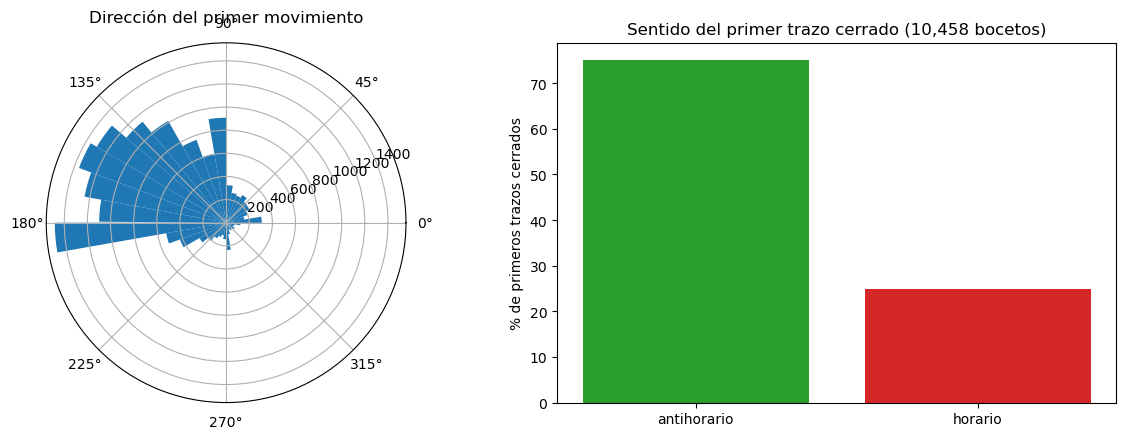

Primer movimiento: {'izquierda': 51.3, 'arriba': 32.7, 'derecha': 9.0, 'abajo': 7.0}
Primeros trazos cerrados: 65 % de los bocetos | antihorario: 75 %, horario: 25 %


In [17]:
first_dir, orient = [], []
for s, sts in zip(eda_sk, strokes_per_sketch):
    first = sts[0]
    first_dir.append(np.arctan2(-first[0, 1], first[0, 0]))       # primer movimiento (y hacia arriba)
    if len(first) >= 5:
        c = np.cumsum(first[:, :2], axis=0) * [1, -1]              # coordenadas con y hacia arriba
        size = max(np.ptp(abs_coords(s), axis=0).max(), 1e-6)
        if np.hypot(*(c[-1] - c[0])) < 0.2 * size:                  # trazo aproximadamente cerrado
            x, y = c[:, 0], c[:, 1]
            area = 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)   # fórmula del área con signo (shoelace)
            orient.append("antihorario" if area > 0 else "horario")
first_dir = np.array(first_dir)
orient = pd.Series(orient)

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax.hist(first_dir, bins=36, color="C0")
ax.set_title("Dirección del primer movimiento", pad=15)
ax = fig.add_subplot(1, 2, 2)
oc = orient.value_counts()
ax.bar(oc.index, oc.values / oc.sum() * 100, color=["C2", "C3"][:len(oc)])
ax.set_ylabel("% de primeros trazos cerrados")
ax.set_title(f"Sentido del primer trazo cerrado ({len(orient):,} bocetos)")
plt.tight_layout()
plt.show()
quad = pd.Series(pd.cut(np.degrees(first_dir), [-180, -135, -45, 45, 135, 180], include_lowest=True,
                        labels=["izquierda", "abajo", "derecha", "arriba", "izquierda "])).astype(str).str.strip()
print("Primer movimiento:", (quad.value_counts(normalize=True) * 100).round(1).to_dict())
print(f"Primeros trazos cerrados: {len(orient) / EDA_N * 100:.0f} % de los bocetos | "
      + ", ".join(f"{k}: {v / oc.sum() * 100:.0f} %" for k, v in oc.items()))

### Hallazgos de la exploración (`apple`)

**Diseño del modelo (3.1)**
- **Dos regímenes de movimiento → MDN.** Dentro de un trazo, la varianza de Δ normalizado es 0.75. En el primer punto
  tras levantar el lápiz es **6.2 (8 veces mayor)**: esos saltos son sólo el 4.7 % de los puntos, pero aportan el
  **28.7 %** del error cuadrático de una predicción constante. Una única gaussiana, o la media que aprende una
  regresión MSE, no describe ambos regímenes. Una mezcla de gaussianas sí.
- **Colas pesadas → normalización.** La curtosis en exceso es 31.7 (Δx) y 21.7 (Δy), frente a 0 en una normal, y hay
  desplazamientos de hasta 1.322 px (48σ). Normalizar por la desviación estándar deja la mayoría de los valores en
  ±1–2. Sólo 1 boceto tiene un salto mayor de 1.000 px, por lo que no hace falta recortar.
- **Memoria → LSTM.** Hay una autocorrelación fuerte entre puntos consecutivos (Δx: +0.51; Δy: +0.38), y la de Δx se
  vuelve **negativa (≈ −0.3) hacia k ≈ 10**: tras recorrer medio contorno, el lápiz va en la dirección opuesta. Es la
  huella del contorno circular, y el modelo sólo la captura si recuerda varios pasos atrás.
- **`pen_state` → pesos por clase.** Levantar el lápiz es casi imposible en la primera mitad del boceto
  (P = 0.008 en el primer 10 %) y muy probable al final (0.26 en el último 10 %), porque primero se dibuja el contorno
  y luego el tallo y la hoja. La tasa de fin es 0 hasta t ≈ 21 y sube hasta 0.36 en t = 60. Con sólo 2.6 % de puntos
  "fin" y 7.0 % "levanta", los pesos 4.54 y 2.75 compensan el desbalance.

**Calidad de los datos (3.2)**
- No hay bocetos con menos de 5 puntos ni demasiado pequeños. Los 1.957 bocetos de **un solo trazo** (12.2 %) y los 329
  con saltos de más de 10σ son **dibujos legítimos**: manzanas completas sin levantar el lápiz, o saltos para dibujar
  el tallo o la hoja. No hay datos basura que filtrar.
- **Sin duplicados**, ni exactos ni casi idénticos, dentro de cada conjunto ni entre ellos: las métricas de prueba no
  están infladas por bocetos repetidos.
- Train, validación y prueba tienen distribuciones prácticamente iguales (D de KS ≤ 0.03 en las cuatro variables): la
  prueba es representativa.

**Estructura del dibujo (3.3)**
- Las manzanas son algo más altas que anchas (aspecto mediano 0.86). La variación natural del aspecto (cociente
  intercuartílico 1.32) es comparable a lo que cambia el aumento de datos (hasta ×1.35): el rango [0.85, 1.15] genera
  variaciones realistas.
- El **primer trazo es el contorno**: contiene en mediana el 72 % de los puntos y es el más largo en el 90 % de los
  bocetos. Los trazos siguientes (tallo y hoja) son cortos (5–8 puntos).
- El dibujo típico **empieza arriba al centro** (la hendidura donde nace el tallo), sale **hacia la izquierda**
  (51 % de los primeros movimientos) y recorre el contorno en **sentido antihorario** (75 % de los primeros trazos
  cerrados). Es un hábito de dibujo muy consistente, que el modelo deberá aprender.

# 4. Preprocesamiento

Pasos (todas las estadísticas se calculan **sólo con los 16.000 bocetos de entrenamiento**, para no filtrar
información de validación/prueba):

1. **Normalización:** Δx y Δy se dividen por su desviación estándar (σx, σy). Se revierte al generar.
2. **Conversión stroke-3 → stroke-5:** `p1 = 1 − pen_lift` (el lápiz sigue en el papel), `p2 = pen_lift`
   (se levanta tras el punto), `p3` = fin del dibujo. Se añade explícitamente un punto final `(0, 0, 0, 0, 1)`.
3. **Truncado y relleno a 200 puntos:** cada boceto conserva a lo sumo 199 puntos reales + el punto de fin
   (≤ 200 en total). Si se trunca, el último punto conservado cierra el trazo (`p2 = 1`). Las posiciones restantes
   se rellenan con `(0, 0, 0, 0, 1)`.
4. **Máscara:** se guarda la longitud real (puntos + punto de fin) de cada secuencia; con ella se construye la
   máscara que excluye el relleno de la pérdida y de las métricas.
5. **Pares entrada → objetivo:** entrada = `[S0, s_1, …, s_199]`, objetivo = `[s_1, …, s_200]`. Para el objetivo
   de `pen_state` se usa el índice de clase (0, 1, 2).

In [18]:
MAX_LEN = 200   # límite obligatorio de puntos por boceto
N_TRAIN, N_VALID, N_TEST = 16_000, 2_000, 2_000   # límite obligatorio de bocetos (80/10/10)

# Desviación estándar de Δx y Δy calculada SOLO con los 16.000 bocetos de entrenamiento
train_pts = np.concatenate([s[:MAX_LEN - 1] for s in raw_train[:N_TRAIN]]).astype(np.float64)
STD_X, STD_Y = train_pts[:, 0].std(), train_pts[:, 1].std()
print(f"σx = {STD_X:.3f} | σy = {STD_Y:.3f}")


def to_stroke5(s3, max_len=MAX_LEN):
    """stroke-3 (N, 3) -> stroke-5 (max_len, 5) normalizado + longitud real (incluye el punto de fin)."""
    s3 = np.asarray(s3[:max_len - 1], dtype=np.float32)   # deja espacio para el punto de fin
    n = len(s3)
    s5 = np.zeros((max_len, 5), dtype=np.float32)
    s5[:n, 0] = s3[:, 0] / STD_X
    s5[:n, 1] = s3[:, 1] / STD_Y
    s5[:n, 2] = 1 - s3[:, 2]          # p1: el lápiz sigue tocando el papel
    s5[:n, 3] = s3[:, 2]              # p2: el lápiz se levanta después de este punto
    s5[n - 1, 2:4] = (0, 1)           # el último punto real siempre cierra su trazo (relevante si se truncó)
    s5[n:, 4] = 1                     # p3: punto de fin del dibujo (posición n) y relleno (posiciones > n)
    return s5, n + 1


def build_tensors(sketches):
    """Construye los tensores de entrada, objetivo y longitudes de un conjunto de bocetos."""
    s5, lens = zip(*(to_stroke5(s) for s in sketches))
    s5 = np.stack(s5)                                   # (N, 200, 5)
    start = np.zeros((len(s5), 1, 5), dtype=np.float32)
    start[:, 0, 2] = 1                                  # token de inicio S0 = (0, 0, 1, 0, 0)
    x = np.concatenate([start, s5[:, :-1]], axis=1)     # entrada:  S0, s_1, ..., s_199
    y = s5                                              # objetivo: s_1, ..., s_200
    return (torch.from_numpy(x), torch.from_numpy(y), torch.tensor(lens, dtype=torch.long))


def length_mask(lens, max_len=MAX_LEN):
    """Máscara booleana (B, max_len): True en los puntos reales, False en el relleno."""
    return torch.arange(max_len, device=lens.device)[None, :] < lens[:, None]


# Verificación con un ejemplo
s5_demo, n_demo = to_stroke5(raw_train[0])
print("Longitud real (con punto de fin):", n_demo)
print("Primeros puntos stroke-5:\n", np.round(s5_demo[:4], 3))
print("Puntos alrededor del final:\n", np.round(s5_demo[n_demo - 2:n_demo + 2], 3))

σx = 27.686 | σy = 32.515
Longitud real (con punto de fin): 44
Primeros puntos stroke-5:
 [[-0.614 -0.554  1.     0.     0.   ]
 [-0.686 -0.431  1.     0.     0.   ]
 [-1.156 -0.062  1.     0.     0.   ]
 [-0.47   0.154  1.     0.     0.   ]]
Puntos alrededor del final:
 [[-0.65  -0.246  0.     1.     0.   ]
 [ 0.     0.     0.     0.     1.   ]
 [ 0.     0.     0.     0.     1.   ]
 [ 0.     0.     0.     0.     1.   ]]


# 5. Split train / validación / prueba

Se aplica el split obligatorio **16.000 / 2.000 / 2.000** (80 / 10 / 10, 20.000 bocetos en total) tomando los
primeros bocetos de cada conjunto provisto en el `.npz` (`train`, `valid`, `test`), de modo que no hay mezcla entre
conjuntos. Validación se usa para *early stopping* y para monitorear el entrenamiento; prueba sólo al final.

In [19]:
sk_train, sk_valid, sk_test = raw_train[:N_TRAIN], raw_valid[:N_VALID], raw_test[:N_TEST]
assert len(sk_train) + len(sk_valid) + len(sk_test) <= 20_000

X_train, Y_train, L_train = build_tensors(sk_train)
X_valid, Y_valid, L_valid = build_tensors(sk_valid)
X_test, Y_test, L_test = build_tensors(sk_test)

for name, X, L in [("train", X_train, L_train), ("valid", X_valid, L_valid), ("test", X_test, L_test)]:
    print(f"{name:5s} -> X {tuple(X.shape)} | puntos reales: {int(L.sum()):,} | "
          f"bocetos truncados: {int((L == MAX_LEN).sum())}")
assert int(L_train.max()) <= MAX_LEN

# Distribución de pen_state en los puntos reales del objetivo de entrenamiento
mask_train = length_mask(L_train)
pen_train = Y_train[..., 2:].argmax(-1)[mask_train]
class_counts = torch.bincount(pen_train, minlength=3).float()
class_freq = class_counts / class_counts.sum()
print("Frecuencia pen_state (dibuja, levanta, fin):", np.round(class_freq.numpy(), 4))

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_train, Y_train, L_train), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
valid_loader = DataLoader(TensorDataset(X_valid, Y_valid, L_valid), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, Y_test, L_test), batch_size=256)

train -> X (16000, 200, 5) | puntos reales: 623,404 | bocetos truncados: 0
valid -> X (2000, 200, 5) | puntos reales: 78,203 | bocetos truncados: 0
test  -> X (2000, 200, 5) | puntos reales: 77,825 | bocetos truncados: 0
Frecuencia pen_state (dibuja, levanta, fin): [0.9043 0.0701 0.0257]


---
> **Nota para el equipo — punto de entrega del notebook base.**
> Las secciones 1 a 5 están completas y ejecutadas. Desde aquí, el notebook debe completarse siguiendo la estructura
> obligatoria del enunciado (secciones 6 a 10, **con estos mismos títulos y en este orden**). Al terminar, borrar esta
> nota y las celdas `TODO`, y verificar que el notebook corre completo con *Run All*.
>
> **Variables y funciones ya disponibles** (definidas en las secciones 3 a 5):
>
> | Nombre | Contenido |
> |---|---|
> | `CATEGORY`, `OUT_DIR` | categoría (`"apple"`) y carpeta de salidas (`salidas/`) |
> | `device`, `SEED` | dispositivo de cómputo (CUDA / MPS / CPU) y semilla |
> | `MAX_LEN` | 200 puntos por boceto |
> | `STD_X`, `STD_Y` | desviaciones estándar de Δx y Δy (sólo train), para normalizar y des-normalizar |
> | `X_train, Y_train, L_train` (y `_valid`, `_test`) | entrada `(N, 200, 5)` con token S0, objetivo `(N, 200, 5)` en stroke-5 normalizado y longitudes reales (incluye el punto de fin) |
> | `train_loader`, `valid_loader`, `test_loader` | `DataLoader` que entregan `(x, y, lens)`; train con `shuffle=True` y lote de 128 |
> | `length_mask(lens)` | máscara booleana `(B, 200)`: `True` en puntos reales, `False` en el relleno |
> | `class_freq` | frecuencia de cada `pen_state` (dibuja, levanta, fin) en los puntos reales de train |
> | `draw_sketch(ax, s)`, `render_sketch(s, archivo)` | dibujan / guardan como PNG un boceto **stroke-3 en píxeles** `(N, 3)` |
> | `sk_train`, `sk_valid`, `sk_test` | bocetos originales (stroke-3) del split 16.000 / 2.000 / 2.000 |
>
> El objetivo de `pen_state` como índice de clase es `y[..., 2:].argmax(-1)` (0 = dibuja, 1 = levanta, 2 = fin), y
> Δx, Δy normalizados son `y[..., :2]`.
---

# 6. Arquitectura y creación del modelo

_Rúbrica: Implementación del modelo (20 %)._ Implementación en PyTorch del modelo, **coherente con el diagrama de la
portada**: LSTM de 2 capas × 512 (dropout 0.2) → dropout → cabeza MDN `Linear(512 → 6·M)` con M = 20 (π softmax,
μx, μy, σx y σy con exp, ρ con tanh) y cabeza `Linear(512 → 3)` para `pen_state`.

In [ ]:
# Arquitectura del modelo (coherente con el diagrama de la portada):
#   LSTM 2 capas x 512 (dropout 0.2) -> dropout -> cabeza MDN Linear(512 -> 6*M) con M = 20
#   y cabeza Linear(512 -> 3) para pen_state.
# Esta celda SOLO crea la arquitectura (pesos inicializados) y verifica dimensiones; no entrena.

M = 20  # numero de componentes de la mezcla de gaussianas


class SketchRNN(nn.Module):
    def __init__(self, input_size=5, hidden_size=512, num_layers=2, num_mixtures=M, dropout=0.2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.M = num_mixtures

        # Codificador recurrente: LSTM de 2 capas x 512, dropout 0.2 entre capas
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout,
        )
        self.drop = nn.Dropout(dropout)

        # Cabeza de regresion MDN: Linear(512 -> 6*M) -> (pi, mu_x, mu_y, sigma_x, sigma_y, rho)
        self.mdn = nn.Linear(hidden_size, 6 * num_mixtures)
        # Cabeza de clasificacion de pen_state: Linear(512 -> 3)
        self.pen = nn.Linear(hidden_size, 3)

    def forward(self, x, state=None):
        """x: (B, T, 5). Devuelve (parametros de la mezcla, logits de pen_state, state)."""
        h, state = self.lstm(x, state)                 # (B, T, 512)
        h = self.drop(h)

        mdn = self.mdn(h)                              # (B, T, 6*M)
        pi, mu_x, mu_y, s_x, s_y, rho = torch.split(mdn, self.M, dim=-1)
        pi = F.softmax(pi, dim=-1)                     # pesos de la mezcla (suman 1)
        s_x = torch.exp(s_x)                           # desviaciones positivas
        s_y = torch.exp(s_y)
        rho = torch.tanh(rho)                          # correlacion en (-1, 1)

        pen_logits = self.pen(h)                       # (B, T, 3)
        return (pi, mu_x, mu_y, s_x, s_y, rho), pen_logits, state


@torch.no_grad()
def generate_sketch(model, max_len=MAX_LEN, temperature=1.0, device=device):
    """Genera un boceto autorregresivamente desde S0 = (0,0,1,0,0).

    Muestrea (Dx, Dy) de la mezcla y pen_state de su distribucion, hasta predecir
    'fin' (clase 2) o llegar a max_len. Devuelve un array stroke-5 normalizado (T, 5).
    No entrena; solo usa el modelo en modo inferencia.
    """
    model.eval()
    x = torch.zeros(1, 1, 5, device=device)
    x[0, 0, 2] = 1.0                                   # token de inicio S0
    state = None
    out = []
    for _ in range(max_len):
        (pi, mu_x, mu_y, s_x, s_y, rho), pen_logits, state = model(x, state)
        pi, mu_x, mu_y = pi[0, -1], mu_x[0, -1], mu_y[0, -1]
        s_x, s_y, rho = s_x[0, -1], s_y[0, -1], rho[0, -1]

        # 1) Elegir componente de la mezcla
        k = torch.multinomial(pi, 1).item()
        # 2) Muestrear (Dx, Dy) de la gaussiana bivariada k
        mean = torch.tensor([mu_x[k], mu_y[k]], device=device)
        sx, sy = s_x[k] * temperature ** 0.5, s_y[k] * temperature ** 0.5
        cov = torch.tensor([[sx * sx, rho[k] * sx * sy],
                            [rho[k] * sx * sy, sy * sy]], device=device)
        dxdy = torch.distributions.MultivariateNormal(mean, cov).sample()

        # 3) Muestrear pen_state de su distribucion
        pen_prob = F.softmax(pen_logits[0, -1] / temperature, dim=-1)
        pen = torch.multinomial(pen_prob, 1).item()

        onehot = F.one_hot(torch.tensor(pen), num_classes=3).float().to(device)
        point = torch.cat([dxdy, onehot])
        out.append(point.cpu().numpy())

        if pen == 2:                                   # estado 'fin'
            break
        x = point.view(1, 1, 5)

    import numpy as np
    return np.stack(out)


# Crear la arquitectura  y verificar dimensiones con un lote
model = SketchRNN().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parametros entrenables: {n_params:,}")

with torch.no_grad():
    (pi, mu_x, mu_y, s_x, s_y, rho), pen_logits, _ = model(X_train[:4].to(device))
print("Formas de salida -> pi:", tuple(pi.shape),
      "| mu_x:", tuple(mu_x.shape),
      "| pen_logits:", tuple(pen_logits.shape))
print("Suma de pi (debe ser ~1):", float(pi[0, 0].sum()))

SketchRNN(
  (lstm): LSTM(5, 512, num_layers=2, batch_first=True, dropout=0.2)
  (drop): Dropout(p=0.2, inplace=False)
  (mdn): Linear(in_features=512, out_features=120, bias=True)
  (pen): Linear(in_features=512, out_features=3, bias=True)
)
Parametros entrenables: 3,227,259
Formas de salida -> pi: (4, 200, 20) | mu_x: (4, 200, 20) | pen_logits: (4, 200, 3)
Suma de pi (debe ser ~1): 1.0000001192092896


# 7. Entrenamiento del modelo

_Rúbrica: Entrenamiento del modelo (30 %)._ Debe incluir:
- **Función de pérdida compuesta**: componente de regresión para Δx, Δy (NLL de la mezcla) + λ · componente de
  clasificación para `pen_state` (entropía cruzada, con pesos por clase a partir de `class_freq`). Ambas promediadas
  **sólo sobre los puntos reales** con `length_mask`.
- **Bucle de entrenamiento** con validación en cada época, selección razonable y justificada de hiperparámetros, y
  medidas contra el sobreajuste (por ejemplo, *early stopping* con el conjunto de validación).
- **Curvas de entrenamiento y validación**.

In [21]:
# TODO (equipo): función de pérdida compuesta enmascarada, bucle de entrenamiento y curvas de train / validación.

# 8. Evaluación del modelo

_Rúbrica: Resultados obtenidos (20 %)._ Sobre el **conjunto de prueba** (usado sólo aquí, al final), con predicción a un
paso y **máscara aplicada**, juntando los puntos de todas las secuencias (métrica global por punto, no por figura):
- **MSE** de Δx y Δy.
- **F1 macro** de `pen_state`.
- **Valor de la función de pérdida**.

In [22]:
# TODO (equipo): evaluación en test_loader (MSE, F1 macro con sklearn.metrics.f1_score(average="macro"), pérdida).

# 9. Generación de ejemplos

_Rúbrica: Resultados obtenidos._ Generación autorregresiva desde el token de inicio S0 = (0, 0, 1, 0, 0), muestreando
(Δx, Δy) de la mezcla y `pen_state` de su distribución, hasta predecir "fin" o llegar a 200 puntos. Des-normalizar con
`STD_X`, `STD_Y`, pasar a stroke-3 y guardar **al menos 3 PNG** con `render_sketch` en `OUT_DIR`.

In [23]:
# TODO (equipo): generar al menos 3 bocetos y guardarlos como PNG (boceto_generado_<categoria>_<i>.png).

# 10. Conclusiones

_TODO (equipo):_ discusión de los resultados, del sobreajuste (comparar entrenamiento, validación y prueba) y de las
limitaciones del modelo. Los hallazgos de la sección 3 pueden servir para interpretar las métricas.